In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Load dataset
df = pd.read_csv("fakenews.csv")

# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

print("Dataset loaded successfully!")
print("Total articles:", len(df))

print("\nNews categories:")
print(df["label"].value_counts())

print("\nSample data:")
print(df[["label", "text"]].head())

Dataset loaded successfully!
Total articles: 2212

News categories:
label
Fake    1110
Real    1102
Name: count, dtype: int64

Sample data:
  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...


In [2]:
# Clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)

print(df[["label", "clean_text"]].head())
print("\nText cleaning completed!")

  label                                         clean_text
0  Real  global economy faces recession the prime minis...
1  Real  earthquake hits chittagong panic spreads gover...
2  Fake  breakthrough in bangladesh s tech industry loc...
3  Fake  dengue situation worsens in the country the pr...
4  Real  new virus outbreak sparks fear government sour...

Text cleaning completed!


In [3]:
# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2,
    max_features=5000
)

tfidf_matrix = vectorizer.fit_transform(df["clean_text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of articles:", tfidf_matrix.shape[0])
print("Number of words:", tfidf_matrix.shape[1])

TF-IDF matrix shape: (2212, 98)
Number of articles: 2212
Number of words: 98


In [4]:
# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2,
    max_features=5000
)

tfidf_matrix = vectorizer.fit_transform(df["clean_text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of articles:", tfidf_matrix.shape[0])
print("Number of words:", tfidf_matrix.shape[1])

TF-IDF matrix shape: (2212, 98)
Number of articles: 2212
Number of words: 98


In [5]:
# Number of topics
num_topics = 5

# Create and train NMF model
nmf_model = NMF(
    n_components=num_topics,
    random_state=42,
    max_iter=200
)

nmf_model.fit(tfidf_matrix)

print("NMF model trained successfully!")
print("Number of topics:", num_topics)

NMF model trained successfully!
Number of topics: 5


In [6]:
# Get vocabulary
words = vectorizer.get_feature_names_out()

# Display top 10 words per topic
for topic_index, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [words[i] for i in top_indices]

    print(f"\nTopic {topic_index + 1}:")
    print(", ".join(top_words))


Topic 1:
experts, significant, advancement, believe, technological, say, natural, quite, conspiracy, calling

Topic 2:
reported, various, parts, incidents, investigating, authorities, city, morning, bangladesh, world

Topic 3:
precautions, help, advise, danger, doctors, basic, avoid, new, moon, astronaut

Topic 4:
prime, minister, chief, guest, attended, ceremony, inauguration, hits, panic, earthquake

Topic 5:
viral, went, social, media, news, noon, new, bangladesh, sparks, virus


In [7]:
# Get topic weights for each article
topic_weights = nmf_model.transform(tfidf_matrix)

# Assign the dominant topic to each article
df["dominant_topic"] = topic_weights.argmax(axis=1) + 1

# Create topic probability/weight columns
topic_columns = [f"Topic_{i+1}" for i in range(num_topics)]

topic_df = pd.DataFrame(
    topic_weights,
    columns=topic_columns,
    index=df.index
)

topic_df["label"] = df["label"]
topic_df["dominant_topic"] = df["dominant_topic"]

print(df[["label", "dominant_topic"]].head(10))

  label  dominant_topic
0  Real               4
1  Real               1
2  Fake               1
3  Fake               4
4  Real               1
5  Fake               3
6  Fake               1
7  Real               1
8  Fake               3
9  Real               2


In [8]:
# Count articles assigned to each topic by category
topic_comparison = pd.crosstab(
    topic_df["dominant_topic"],
    topic_df["label"]
)

print("Topic Distribution: Real vs Fake News\n")
print(topic_comparison)

# Compare average topic weights
topic_relevance = (
    topic_df.groupby("label")[topic_columns]
    .mean()
    .round(4)
)

print("\nAverage Topic Weights by Category:\n")
print(topic_relevance)

Topic Distribution: Real vs Fake News

label           Fake  Real
dominant_topic            
1                655   647
2                120   102
3                117   111
4                108   112
5                110   130

Average Topic Weights by Category:

       Topic_1  Topic_2  Topic_3  Topic_4  Topic_5
label                                             
Fake    0.0314   0.0297   0.0291   0.0292   0.0244
Real    0.0309   0.0264   0.0277   0.0308   0.0285


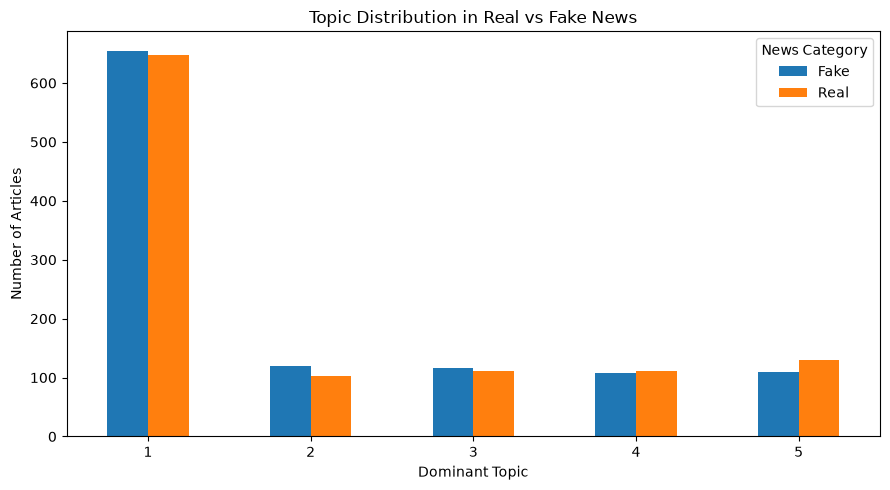

In [9]:
# Plot topic distribution
topic_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Topic Distribution in Real vs Fake News")
plt.xlabel("Dominant Topic")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.legend(title="News Category")
plt.tight_layout()
plt.show()

In [10]:
# Save article-level topic assignments
df.to_csv("T27_topic_assignments.csv", index=False)

# Save topic weights
topic_df.to_csv("T27_topic_weights.csv", index=False)

# Save topic distribution comparison
topic_comparison.to_csv("T27_topic_comparison.csv")

# Save average topic relevance
topic_relevance.to_csv("T27_topic_relevance.csv")

# Display final results
print("Topic Distribution:\n")
print(topic_comparison)

print("\nAverage Topic Weights:\n")
print(topic_relevance)

# Display top words for each topic
words = vectorizer.get_feature_names_out()

print("\nRecurring Themes:")
for topic_index, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [words[i] for i in top_indices]

    print(f"Topic {topic_index + 1}: {', '.join(top_words)}")

print("\nComparative topic analysis completed successfully!")

Topic Distribution:

label           Fake  Real
dominant_topic            
1                655   647
2                120   102
3                117   111
4                108   112
5                110   130

Average Topic Weights:

       Topic_1  Topic_2  Topic_3  Topic_4  Topic_5
label                                             
Fake    0.0314   0.0297   0.0291   0.0292   0.0244
Real    0.0309   0.0264   0.0277   0.0308   0.0285

Recurring Themes:
Topic 1: experts, significant, advancement, believe, technological, say, natural, quite, conspiracy, calling
Topic 2: reported, various, parts, incidents, investigating, authorities, city, morning, bangladesh, world
Topic 3: precautions, help, advise, danger, doctors, basic, avoid, new, moon, astronaut
Topic 4: prime, minister, chief, guest, attended, ceremony, inauguration, hits, panic, earthquake
Topic 5: viral, went, social, media, news, noon, new, bangladesh, sparks, virus

Comparative topic analysis completed successfully!
